In [21]:
import matplotlib.pyplot as plt
import numpy as np
import random

from typing import TypeAlias
from collections.abc import Iterable, Callable
from matplotlib.axes import Axes

from sklearn import datasets
from itertools import product

from engine import Value
from nn import MLP

In [22]:
LossFn: TypeAlias = Callable[
    [MLP, Iterable[Value], Iterable[float]], Value
]
AccuracyFn: TypeAlias = Callable[
    [Iterable[Value], Iterable[float]], float
]
Loss: TypeAlias = float
Accuracy: TypeAlias = float
LearningRate: TypeAlias = float
LearningRateScheduler: TypeAlias = Callable[[int, int], float]


def optimize(
    model: MLP,
    loss_fn: LossFn,
    accuracy_fn: AccuracyFn,
    X: Iterable[Iterable[float]],
    y: Iterable[float],
    *,
    num_steps: int = 50,
    learning_rate_scheduler: LearningRateScheduler = lambda i, n: 1e-4,
) -> list[tuple[Loss, Accuracy, LearningRate]]:
    """Optimize model parameters in place using full-batch gradient descent.

    Args:
        model: Model whose parameters are updated.
        loss_fn: Computes differentiable loss from the model, raw prediction
            scores, and targets, with any additional arguments bound.
        accuracy_fn: Computes accuracy from raw prediction scores and
            targets.
        X: Nonempty collection of input rows.
        y: Targets, one per input row.
        num_steps: Number of updates; zero returns an empty history.
        learning_rate_scheduler: Maps a zero-based step to a learning rate.
            Defaults to a constant 1e-4.

    Returns:
        Tuples of pre-update loss, pre-update accuracy, and the learning
        rate used for that update.

    Raises:
        ValueError: If num_steps is negative, inputs are empty, or input
            and target counts differ.
    """
    if num_steps < 0:
        raise ValueError("num_steps must be nonnegative.")
    inputs = [list(map(Value, xrow)) for xrow in X]
    e_outputs = list(y)
    if not inputs:
        raise ValueError("Inputs must not be empty.")
    if len(inputs) != len(e_outputs):
        raise ValueError("Input and target counts must match.")

    metrics: list[tuple[Loss, Accuracy, LearningRate]] = []

    for i in range(num_steps):
        scores = list(s[0] for s in map(model, inputs))
        total_loss = loss_fn(model, scores, e_outputs)
        accuracy = accuracy_fn(scores, e_outputs)
        model.zero_grad()
        total_loss.backward()
        learning_rate = learning_rate_scheduler(i, num_steps)
        for p in model.parameters():
            p.data -= learning_rate * p.grad
        metrics.append((total_loss.data, accuracy, learning_rate))
        
        if i % 1 == 0:
            print(
                f"step {i} loss {total_loss.data}, "
                f"accuracy {accuracy * 100:.4f}%"
            )

    return metrics

In [23]:
DataLossFn: TypeAlias = Callable[
    [Iterable[Value], Iterable[float]], Value
]
RegLossFn: TypeAlias = Callable[
    [MLP], Value
]


def loss(model: MLP,
         pred_y: Iterable[Value], expected_y: Iterable[float],
         data_loss_fn: DataLossFn,
         reg_loss_fn: RegLossFn) -> Value:
    return data_loss_fn(pred_y, expected_y) + reg_loss_fn(model)

In [24]:
def bce_loss(preds: Iterable[Value], ys: Iterable[float]) -> Value:
    """Compute mean binary cross-entropy from raw logits.

    Args:
        preds: Raw model scores, without applying sigmoid.
        ys: Corresponding binary targets (zero or one).

    Returns:
        Mean loss as a differentiable Value.

    Raises:
        ValueError: If predictions are empty or lengths differ.
    """
    preds = tuple(preds)
    if not preds:
        raise ValueError("Predictions must not be empty.")
    return sum(
        (
            (1 - y) * p + (1 + (-p).exp()).log()
            if p.data >= 0
            else -y * p + (1 + p.exp()).log()
            for p, y in zip(preds, ys, strict=True)
        ),
        start=Value(0.0)
    ) / len(preds)


def bce_acc(pred_y: Iterable[Value], expected_y: Iterable[float]) -> float:
    """Return binary accuracy from raw logits using a zero threshold.

    Raises:
        ValueError: If predictions are empty or lengths differ.
    """
    pred_y = tuple(pred_y)
    if not pred_y:
        raise ValueError("Predictions must not be empty.")
    return sum(
        float((pred.data >= 0) == target)
        for pred, target in zip(pred_y, expected_y, strict=True)
    ) / len(pred_y)

In [25]:
def hinge_loss(preds: Iterable[Value], ys: Iterable[float]) -> Value:
    """Compute mean hinge loss from raw scores and zero/one labels.

    Targets are mapped to -1/+1 so each loss is max(0, 1 - target * score).

    Args:
        preds: Raw model scores, without applying sigmoid.
        ys: Corresponding binary targets (zero or one).

    Returns:
        Mean loss as a differentiable Value.

    Raises:
        ValueError: If predictions are empty or lengths differ.
    """
    preds = tuple(preds)
    if not preds:
        raise ValueError("Predictions must not be empty.")
    return sum(
        ((1 - (2 * y - 1) * p).relu()
         for p, y in zip(preds, ys, strict=True)),
        start=Value(0.0),
    ) / len(preds)


def hinge_acc(pred_y: Iterable[Value], expected_y: Iterable[float]) -> float:
    """Return zero-threshold accuracy for hinge scores and zero/one labels.

    Raises:
        ValueError: If predictions are empty or lengths differ.
    """
    return bce_acc(pred_y, expected_y)

In [26]:
def l2_reg_loss(model: MLP, *, alpha: float = 1e-4) -> Value:
    return alpha * sum((p ** 2 for p in model.parameters()), start=Value(0.0))

In [27]:
def linear_lr_decay(step_num: int, num_steps: int) -> float:
    return 1.0 - 0.9 * (step_num / num_steps)

In [28]:
EXPERIMENT_SEED = 42
N_SAMPLES = 100

xor_X, xor_clusters = datasets.make_blobs(
    n_samples=N_SAMPLES,
    centers=[(-1, -1), (-1, 1), (1, -1), (1, 1)],
    cluster_std=0.25, random_state=EXPERIMENT_SEED,
)
xor_y = np.isin(xor_clusters, [1, 2]).astype(int)

dataset_registry = {
    "concentric_circles": datasets.make_circles(
        n_samples=N_SAMPLES, noise=0.1, factor=0.2,
        random_state=EXPERIMENT_SEED,
    ),
    "two_moons": datasets.make_moons(
        n_samples=N_SAMPLES, noise=0.15, random_state=EXPERIMENT_SEED,
    ),
    "overlapping_blobs": datasets.make_blobs(
        n_samples=N_SAMPLES, centers=[(-0.75, -0.75), (0.75, 0.75)],
        cluster_std=0.8, random_state=EXPERIMENT_SEED,
    ),
    "xor": (xor_X, xor_y),
}

loss_and_acc_fns = {
    "bce_l2": (
        lambda model, pred_y, y: loss(model, pred_y, y, bce_loss, l2_reg_loss),
        bce_acc
    ),
    "hinge_l2": (
        lambda model, pred_y, y: loss(
            model, pred_y, y, hinge_loss, l2_reg_loss
        ),
        hinge_acc
    )
}

lr_scheduler = {
    "linear_decay": linear_lr_decay,
    "constant": lambda i, n: 1.0,
}

In [29]:
def plot_decision_boundary(
    model: MLP,
    X: Iterable[Iterable[float]],
    y: Iterable[float],
    *,
    loss_name: str,
    scheduler_name: str,
    grid_size: int = 80,
) -> Axes:
    """Plot binary data and a model's zero-logit decision boundary.

    Args:
        model: Trained model with one raw output score per input.
        X: Nonempty collection of two-dimensional input rows.
        y: Corresponding binary labels (zero or one).
        loss_name: Name of the training loss, displayed in the title.
        scheduler_name: Name of the learning-rate scheduler for the title.
        grid_size: Number of grid points along each axis, at least two.
            Larger grids require more scalar model evaluations.

    Returns:
        Matplotlib axes containing the data and predicted class regions.
        A boundary is drawn if grid scores span both sides of zero.

    Raises:
        ValueError: If data is empty, not finite or two-dimensional,
            labels are not matching binary targets, or grid_size < 2.

    Example:
        plot_decision_boundary(
            model, *dataset_registry["concentric_circles"],
            loss_name="bce_l2", scheduler_name="linear_decay",
        )
        plt.show()
    """
    points = np.asarray([list(row) for row in X], dtype=float)
    targets = np.asarray(list(y), dtype=float)
    if points.ndim != 2 or points.shape[1] != 2 or len(points) == 0:
        raise ValueError("Inputs must contain nonempty rows of two features.")
    if not np.isfinite(points).all():
        raise ValueError("Inputs must be finite.")
    if targets.shape != (len(points),) or not np.isin(targets, [0, 1]).all():
        raise ValueError("Labels must match inputs and contain only 0 or 1.")
    if grid_size < 2:
        raise ValueError("grid_size must be at least two.")

    xs = np.linspace(points[:, 0].min() - 0.3,
                     points[:, 0].max() + 0.3, grid_size)
    ys = np.linspace(points[:, 1].min() - 0.3,
                     points[:, 1].max() + 0.3, grid_size)
    xx, yy = np.meshgrid(xs, ys)
    scores = np.asarray([
        model([float(a), float(b)])[0].data
        for a, b in zip(xx.ravel(), yy.ravel(), strict=True)
    ]).reshape(xx.shape)

    _, ax = plt.subplots(figsize=(5, 5))
    ax.contourf(xx, yy, (scores >= 0).astype(int),
                levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.25)
    if scores.min() < 0 < scores.max():
        ax.contour(xx, yy, scores, levels=[0], colors="black")
    ax.scatter(points[:, 0], points[:, 1], c=targets, cmap="coolwarm",
               vmin=0, vmax=1, edgecolors="black", s=20)
    ax.set(
        xlabel="x1", ylabel="x2",
        title=(f"Decision boundary\nLoss: {loss_name} | "
               f"Scheduler: {scheduler_name}"),
    )
    ax.set_aspect("equal")
    return ax

In [30]:
def plot_learning_curves(
    metrics: Iterable[tuple[Loss, Accuracy, LearningRate]],
    *,
    title: str,
) -> tuple[Axes, Axes]:
    """Plot pre-update training loss and accuracy against update index.

    Loss includes regularization. Compare accuracy across different loss
    functions; BCE and hinge loss magnitudes are not directly comparable.

    Args:
        metrics: Optimizer history of loss, accuracy, and learning rate.
        title: Experiment label displayed above both plots.

    Returns:
        Loss and accuracy axes, respectively.

    Raises:
        ValueError: If the history is empty.
    """
    history = list(metrics)
    if not history:
        raise ValueError("Training history must not be empty.")
    steps = np.arange(len(history))
    fig, (loss_ax, accuracy_ax) = plt.subplots(1, 2, figsize=(10, 4))
    loss_ax.plot(steps, [entry[0] for entry in history])
    loss_ax.set(xlabel="Update index (before update)", ylabel="Training loss")
    accuracy_ax.plot(steps, [100 * entry[1] for entry in history])
    accuracy_ax.set(xlabel="Update index (before update)",
                    ylabel="Training accuracy (%)", ylim=(0, 100))
    fig.suptitle(title)
    fig.tight_layout()
    return loss_ax, accuracy_ax

concentric_circles bce_l2 linear_decay
step 0 loss 0.9217695663655331, accuracy 53.0000%
step 1 loss 0.6431659911632245, accuracy 60.0000%
step 2 loss 1.0232990886529612, accuracy 50.0000%
step 3 loss 1.383976923025071, accuracy 50.0000%
step 4 loss 0.9823243333791154, accuracy 61.0000%
step 5 loss 0.8507617007294828, accuracy 50.0000%
step 6 loss 0.6832847760753747, accuracy 66.0000%
step 7 loss 0.5277601798595937, accuracy 73.0000%
step 8 loss 0.4488402090647614, accuracy 74.0000%
step 9 loss 0.34890297976796775, accuracy 96.0000%
step 10 loss 0.3029799942133962, accuracy 85.0000%
step 11 loss 0.25475098549342046, accuracy 99.0000%
step 12 loss 0.22162018465541494, accuracy 99.0000%
step 13 loss 0.19635748851343449, accuracy 100.0000%
step 14 loss 0.1777608052598134, accuracy 100.0000%
step 15 loss 0.16308767946610214, accuracy 100.0000%
step 16 loss 0.15101323549370332, accuracy 100.0000%
step 17 loss 0.14077435750773684, accuracy 100.0000%
step 18 loss 0.13197165634108887, accuracy

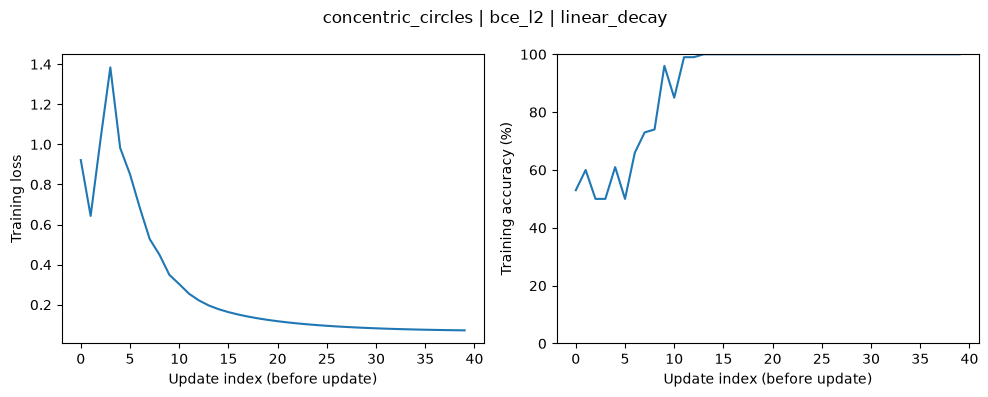

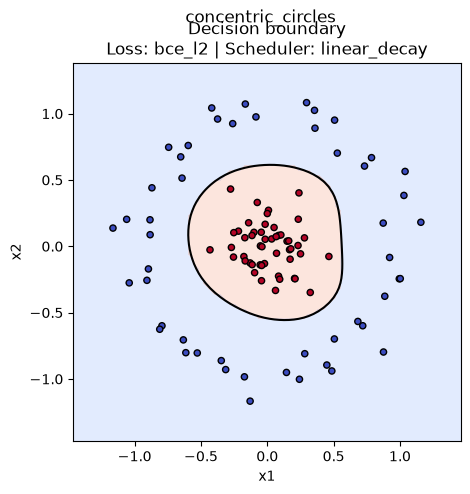

concentric_circles bce_l2 constant
step 0 loss 0.9217695663655331, accuracy 53.0000%
step 1 loss 0.6431659911632245, accuracy 60.0000%
step 2 loss 1.0452079234728584, accuracy 50.0000%
step 3 loss 1.4843172761012682, accuracy 50.0000%
step 4 loss 1.056673399804417, accuracy 61.0000%
step 5 loss 1.094197756580764, accuracy 50.0000%
step 6 loss 0.7809827351729608, accuracy 63.0000%
step 7 loss 0.6740198520443095, accuracy 51.0000%
step 8 loss 0.6492334076892003, accuracy 67.0000%
step 9 loss 0.5666595095892598, accuracy 59.0000%
step 10 loss 0.6269430758351, accuracy 69.0000%
step 11 loss 0.4601541339380188, accuracy 79.0000%
step 12 loss 0.3457715377112252, accuracy 80.0000%
step 13 loss 0.2469983172292644, accuracy 97.0000%
step 14 loss 0.20047753432756837, accuracy 99.0000%
step 15 loss 0.16663345959946863, accuracy 99.0000%
step 16 loss 0.14595554477221045, accuracy 100.0000%
step 17 loss 0.13092724797348249, accuracy 100.0000%
step 18 loss 0.11888758363865673, accuracy 100.0000%
ste

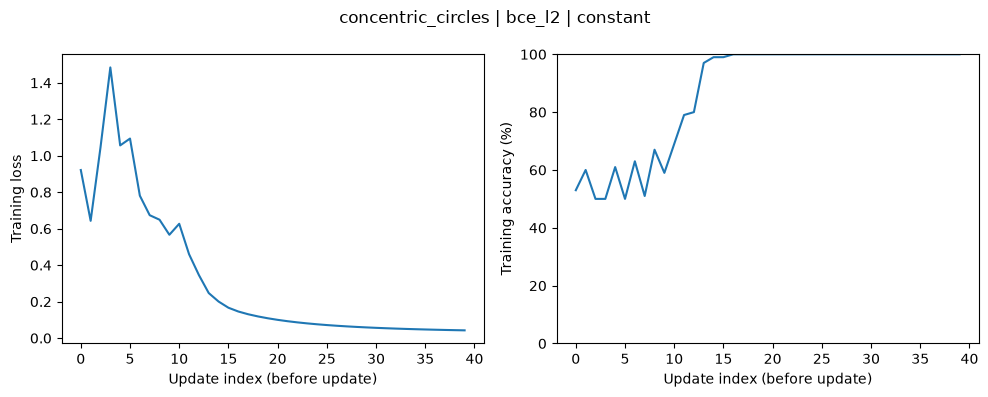

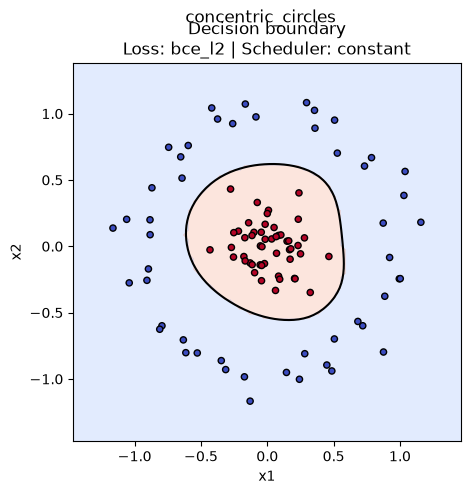

concentric_circles hinge_l2 linear_decay
step 0 loss 1.201201868149831, accuracy 53.0000%
step 1 loss 1.3544279101971353, accuracy 51.0000%
step 2 loss 2.48894641245987, accuracy 49.0000%
step 3 loss 1.0867600444410093, accuracy 65.0000%
step 4 loss 1.7923130175704716, accuracy 50.0000%
step 5 loss 0.9512982800654788, accuracy 50.0000%
step 6 loss 1.3564017175089211, accuracy 50.0000%
step 7 loss 0.8923725519810753, accuracy 66.0000%
step 8 loss 0.4552209040210767, accuracy 87.0000%
step 9 loss 0.5539116163857651, accuracy 88.0000%
step 10 loss 0.7913410212707115, accuracy 70.0000%
step 11 loss 0.8005986565579138, accuracy 59.0000%
step 12 loss 0.8812621094224917, accuracy 66.0000%
step 13 loss 0.4989204578097636, accuracy 80.0000%
step 14 loss 0.6281612409569295, accuracy 84.0000%
step 15 loss 0.404965743474175, accuracy 80.0000%
step 16 loss 0.4270489433592298, accuracy 78.0000%
step 17 loss 0.195569010483789, accuracy 95.0000%
step 18 loss 0.1402787198933767, accuracy 98.0000%
step 

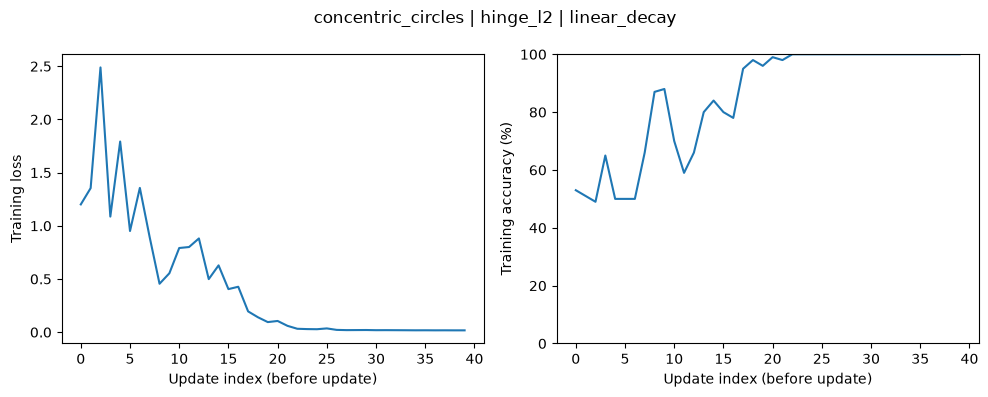

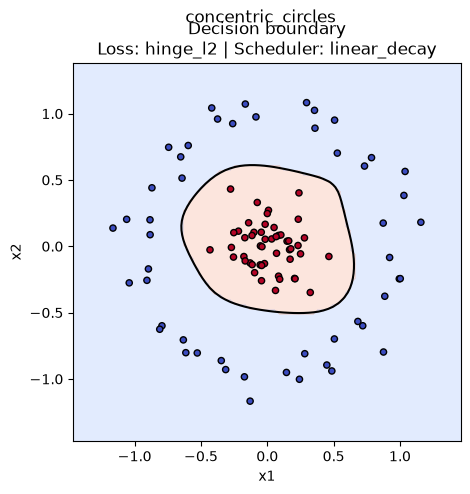

concentric_circles hinge_l2 constant
step 0 loss 1.201201868149831, accuracy 53.0000%
step 1 loss 1.3544279101971353, accuracy 51.0000%
step 2 loss 2.531404711745067, accuracy 49.0000%
step 3 loss 1.2007898995241557, accuracy 64.0000%
step 4 loss 1.8955026702800892, accuracy 50.0000%
step 5 loss 0.9880315935863686, accuracy 56.0000%
step 6 loss 1.4767294156804094, accuracy 50.0000%
step 7 loss 0.9877834721950611, accuracy 64.0000%
step 8 loss 0.6082967636359151, accuracy 73.0000%
step 9 loss 0.5053872555506794, accuracy 90.0000%
step 10 loss 1.2000840213420332, accuracy 52.0000%
step 11 loss 1.6190802512353428, accuracy 50.0000%
step 12 loss 0.9941872842312337, accuracy 73.0000%
step 13 loss 0.7936775015401253, accuracy 68.0000%
step 14 loss 1.037965167022544, accuracy 73.0000%
step 15 loss 0.6803480845613281, accuracy 76.0000%
step 16 loss 0.6085337590823127, accuracy 74.0000%
step 17 loss 0.23837855273888595, accuracy 92.0000%
step 18 loss 0.38393080763660503, accuracy 84.0000%
step 

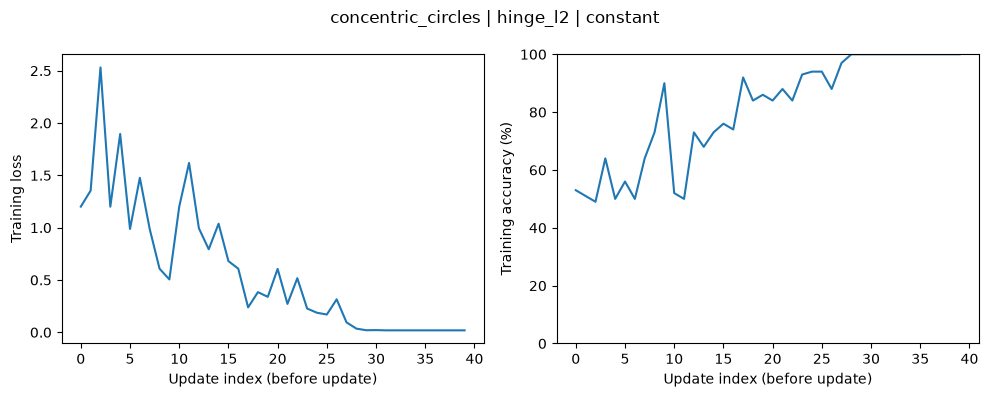

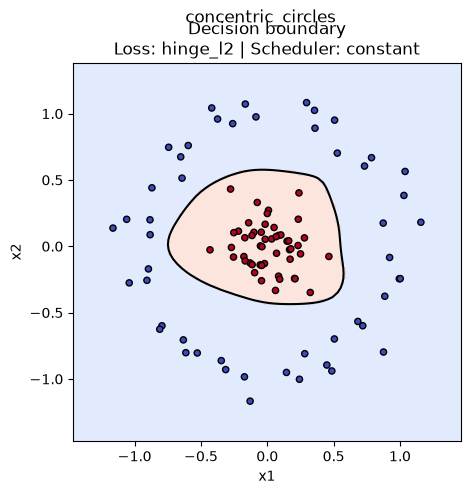

two_moons bce_l2 linear_decay
step 0 loss 0.9405080252386604, accuracy 50.0000%
step 1 loss 0.7433585445486697, accuracy 75.0000%
step 2 loss 0.8844056138453281, accuracy 76.0000%
step 3 loss 0.40004548625518765, accuracy 85.0000%
step 4 loss 0.3529639600063636, accuracy 86.0000%
step 5 loss 0.3212845756366335, accuracy 88.0000%
step 6 loss 0.2969942017477166, accuracy 88.0000%
step 7 loss 0.2766454140446905, accuracy 90.0000%
step 8 loss 0.26018330380272076, accuracy 90.0000%
step 9 loss 0.24766233685688496, accuracy 90.0000%
step 10 loss 0.23770384798360433, accuracy 90.0000%
step 11 loss 0.22927611600326078, accuracy 91.0000%
step 12 loss 0.22183449330629143, accuracy 92.0000%
step 13 loss 0.2150900196403975, accuracy 93.0000%
step 14 loss 0.20888132751217509, accuracy 93.0000%
step 15 loss 0.20311060964098973, accuracy 93.0000%
step 16 loss 0.19771620285096211, accuracy 93.0000%
step 17 loss 0.1926573117608961, accuracy 93.0000%
step 18 loss 0.18790602323770123, accuracy 93.0000%
s

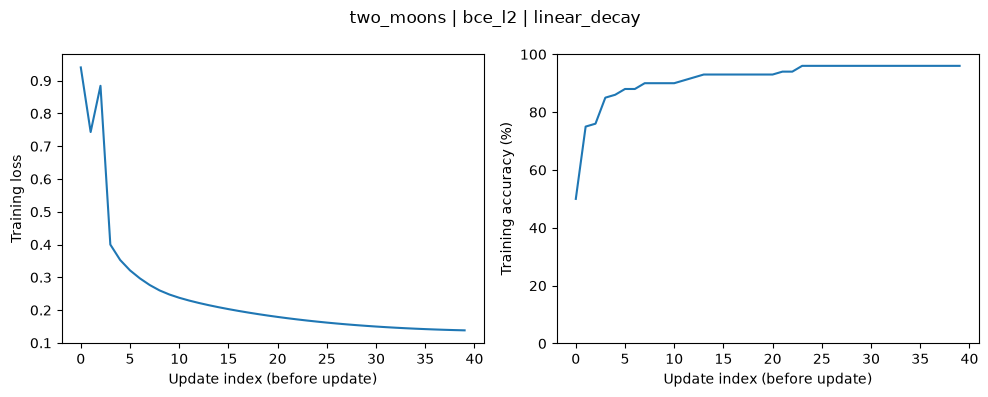

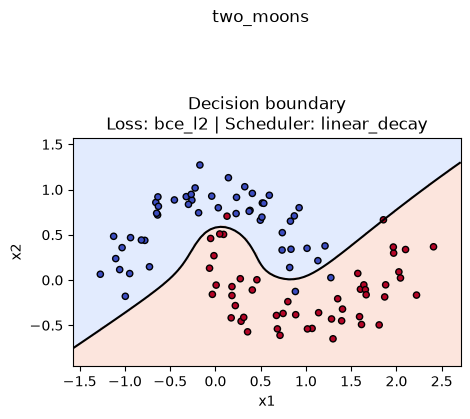

two_moons bce_l2 constant
step 0 loss 0.9405080252386604, accuracy 50.0000%
step 1 loss 0.7433585445486697, accuracy 75.0000%
step 2 loss 0.9070446911620613, accuracy 76.0000%
step 3 loss 0.3993815616879921, accuracy 85.0000%
step 4 loss 0.3516169115781642, accuracy 86.0000%
step 5 loss 0.3207352724447452, accuracy 88.0000%
step 6 loss 0.2959064774688727, accuracy 88.0000%
step 7 loss 0.27386579988747956, accuracy 90.0000%
step 8 loss 0.25610380413646816, accuracy 90.0000%
step 9 loss 0.24274511924217915, accuracy 92.0000%
step 10 loss 0.23236617593654987, accuracy 92.0000%
step 11 loss 0.22308846902340976, accuracy 93.0000%
step 12 loss 0.21545553607442675, accuracy 91.0000%
step 13 loss 0.20848181351135744, accuracy 93.0000%
step 14 loss 0.20416989575484545, accuracy 92.0000%
step 15 loss 0.20219546519914844, accuracy 93.0000%
step 16 loss 0.20772536482904205, accuracy 95.0000%
step 17 loss 0.22642844409027307, accuracy 92.0000%
step 18 loss 0.26757005417572527, accuracy 94.0000%
ste

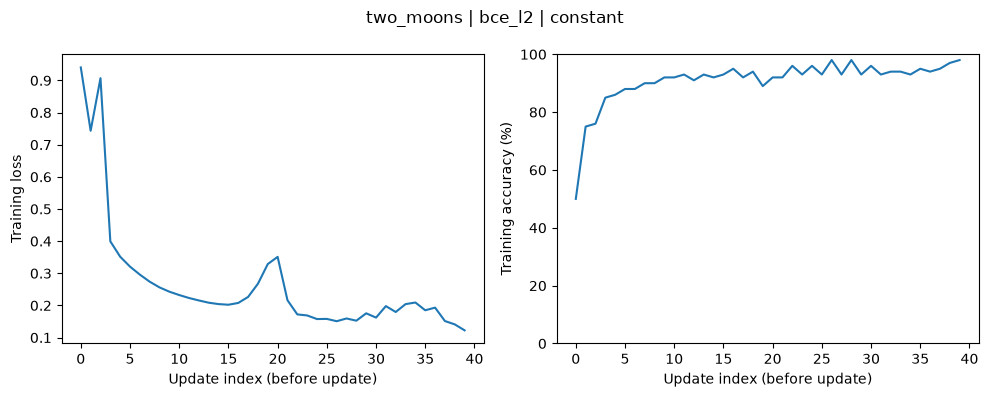

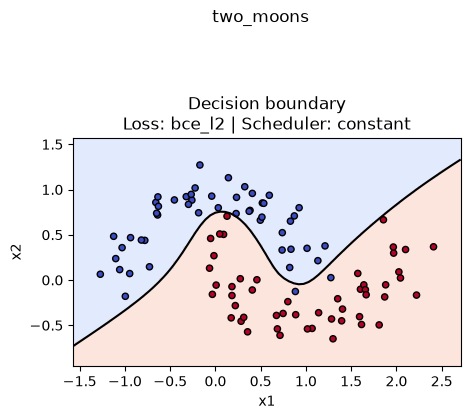

two_moons hinge_l2 linear_decay
step 0 loss 1.2486331680692384, accuracy 50.0000%
step 1 loss 1.2855678157511419, accuracy 62.0000%
step 2 loss 1.4332315858933025, accuracy 73.0000%
step 3 loss 0.4681340211652355, accuracy 82.0000%
step 4 loss 0.7604959627367418, accuracy 53.0000%
step 5 loss 1.0019160140053216, accuracy 81.0000%
step 6 loss 0.5116761539655936, accuracy 84.0000%
step 7 loss 0.24269525558185234, accuracy 90.0000%
step 8 loss 0.24277531049292017, accuracy 93.0000%
step 9 loss 0.2575839119830234, accuracy 89.0000%
step 10 loss 0.18231968570342497, accuracy 93.0000%
step 11 loss 0.2819407297857809, accuracy 91.0000%
step 12 loss 0.6000428676649951, accuracy 84.0000%
step 13 loss 0.3258931221981214, accuracy 88.0000%
step 14 loss 0.16965775325301508, accuracy 93.0000%
step 15 loss 0.16606243681213806, accuracy 97.0000%
step 16 loss 0.2104109701011476, accuracy 91.0000%
step 17 loss 0.1300983538725434, accuracy 96.0000%
step 18 loss 0.11937674997753958, accuracy 96.0000%
ste

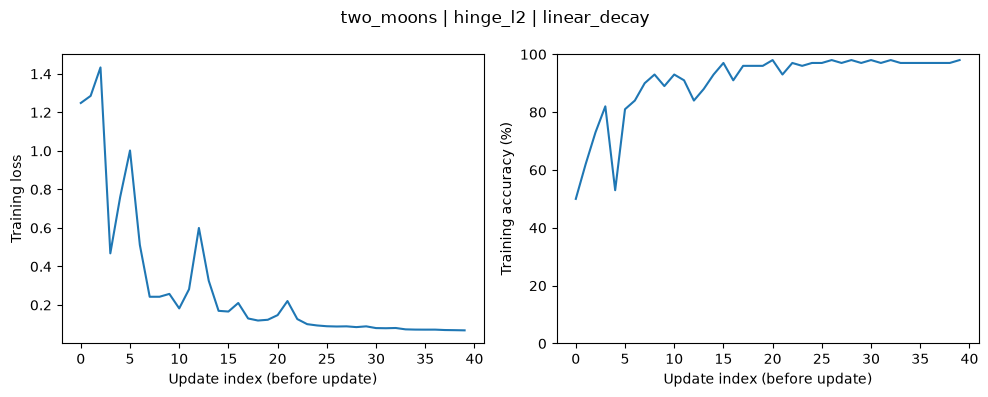

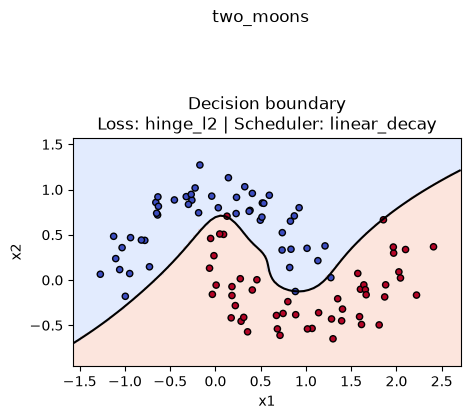

two_moons hinge_l2 constant
step 0 loss 1.2486331680692384, accuracy 50.0000%
step 1 loss 1.2855678157511419, accuracy 62.0000%
step 2 loss 1.4493550939617497, accuracy 73.0000%
step 3 loss 0.4506701131835229, accuracy 82.0000%
step 4 loss 0.7957137290256485, accuracy 53.0000%
step 5 loss 1.1961361108468924, accuracy 81.0000%
step 6 loss 0.564623490935716, accuracy 84.0000%
step 7 loss 0.26043509988145275, accuracy 89.0000%
step 8 loss 0.31120259633707437, accuracy 89.0000%
step 9 loss 0.623639292268827, accuracy 81.0000%
step 10 loss 1.272825296610115, accuracy 78.0000%
step 11 loss 0.507874542524015, accuracy 85.0000%
step 12 loss 0.24977585770170874, accuracy 88.0000%
step 13 loss 0.3108342638845271, accuracy 92.0000%
step 14 loss 0.5161870226902985, accuracy 87.0000%
step 15 loss 0.3024199602427974, accuracy 89.0000%
step 16 loss 0.20227686034973888, accuracy 96.0000%
step 17 loss 0.2888732316160946, accuracy 90.0000%
step 18 loss 0.28427012229570836, accuracy 91.0000%
step 19 loss

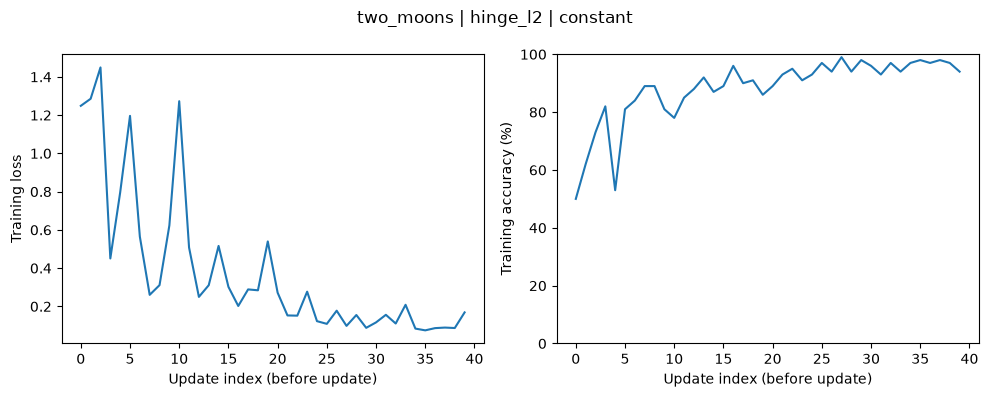

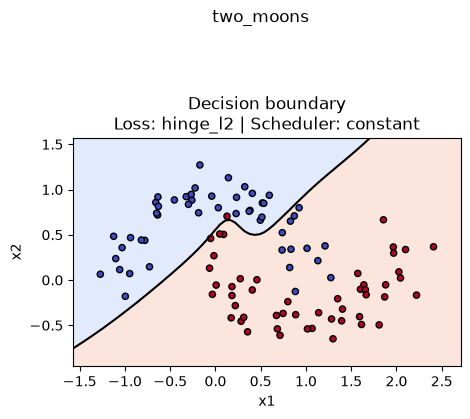

overlapping_blobs bce_l2 linear_decay
step 0 loss 0.6113527979048458, accuracy 54.0000%
step 1 loss 0.3222611634607341, accuracy 91.0000%
step 2 loss 0.24479169495688224, accuracy 92.0000%
step 3 loss 0.19065509691406912, accuracy 92.0000%
step 4 loss 0.18003191636725488, accuracy 94.0000%
step 5 loss 0.17351775403587213, accuracy 92.0000%
step 6 loss 0.1686011135574938, accuracy 92.0000%
step 7 loss 0.16464613930855518, accuracy 92.0000%
step 8 loss 0.16137678891099616, accuracy 93.0000%
step 9 loss 0.15863175504760457, accuracy 92.0000%
step 10 loss 0.15629835892365113, accuracy 93.0000%
step 11 loss 0.15429332110049068, accuracy 93.0000%
step 12 loss 0.15255453374416358, accuracy 93.0000%
step 13 loss 0.15103068441435735, accuracy 93.0000%
step 14 loss 0.14968272061968885, accuracy 93.0000%
step 15 loss 0.1484795936847095, accuracy 93.0000%
step 16 loss 0.14739754507432512, accuracy 93.0000%
step 17 loss 0.1464179794077949, accuracy 93.0000%
step 18 loss 0.14552640453971122, accurac

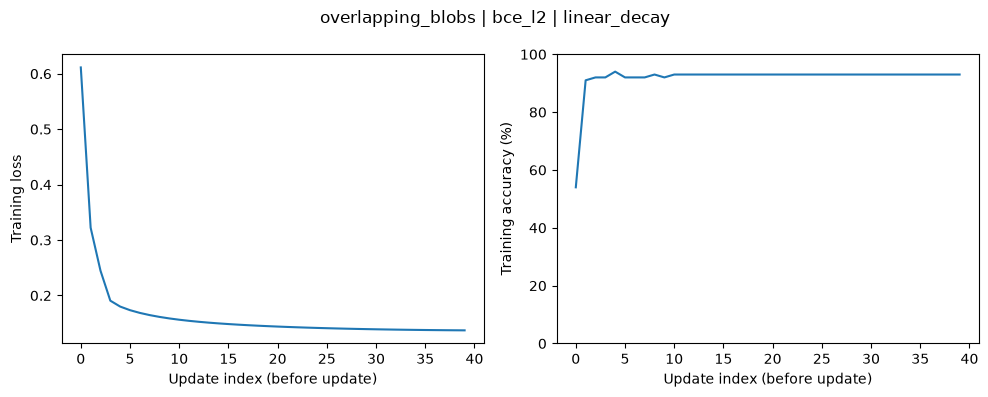

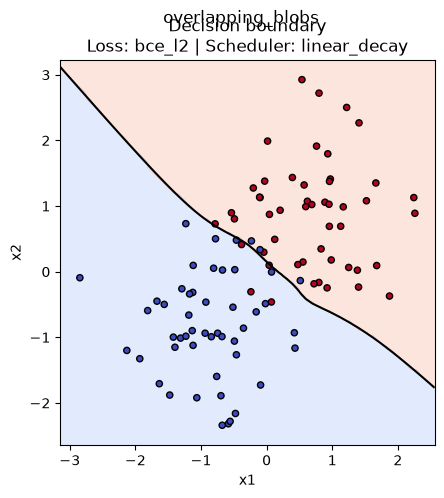

overlapping_blobs bce_l2 constant
step 0 loss 0.6113527979048458, accuracy 54.0000%
step 1 loss 0.3222611634607341, accuracy 91.0000%
step 2 loss 0.24908952107165466, accuracy 92.0000%
step 3 loss 0.1930229998338815, accuracy 92.0000%
step 4 loss 0.18128693720263914, accuracy 93.0000%
step 5 loss 0.17370934247054676, accuracy 92.0000%
step 6 loss 0.16815416586541704, accuracy 94.0000%
step 7 loss 0.16379358990078763, accuracy 92.0000%
step 8 loss 0.16033882329198643, accuracy 94.0000%
step 9 loss 0.15749198678302828, accuracy 92.0000%
step 10 loss 0.1553044492222779, accuracy 94.0000%
step 11 loss 0.15351044434806999, accuracy 92.0000%
step 12 loss 0.15236330616854474, accuracy 94.0000%
step 13 loss 0.15151305330023357, accuracy 92.0000%
step 14 loss 0.15142565073075182, accuracy 94.0000%
step 15 loss 0.1514743516790892, accuracy 92.0000%
step 16 loss 0.1522468957605318, accuracy 93.0000%
step 17 loss 0.15274591493352568, accuracy 93.0000%
step 18 loss 0.1533387268071012, accuracy 93.0

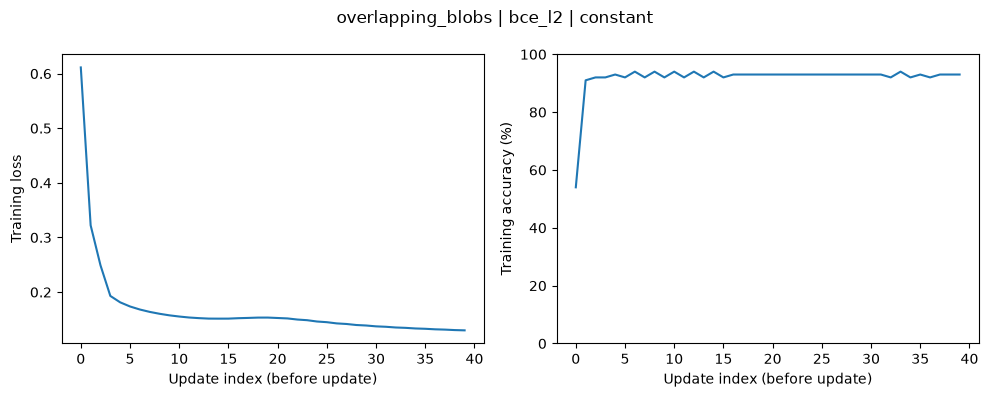

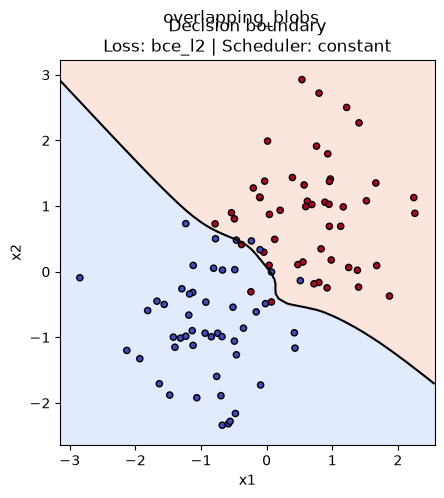

overlapping_blobs hinge_l2 linear_decay
step 0 loss 0.78393029958802, accuracy 54.0000%
step 1 loss 1.1107284119301006, accuracy 65.0000%
step 2 loss 0.7506482660046778, accuracy 84.0000%
step 3 loss 0.4434833557634622, accuracy 91.0000%
step 4 loss 0.2891170895783602, accuracy 93.0000%
step 5 loss 0.24772393544599058, accuracy 92.0000%
step 6 loss 0.2461281179626788, accuracy 94.0000%
step 7 loss 0.22512784937213628, accuracy 93.0000%
step 8 loss 0.21702160571502419, accuracy 94.0000%
step 9 loss 0.20565280789684162, accuracy 94.0000%
step 10 loss 0.20033335952037118, accuracy 94.0000%
step 11 loss 0.19722305545908955, accuracy 93.0000%
step 12 loss 0.1915350534402308, accuracy 94.0000%
step 13 loss 0.18795987893901894, accuracy 94.0000%
step 14 loss 0.1831804625407923, accuracy 94.0000%
step 15 loss 0.17989554493345072, accuracy 94.0000%
step 16 loss 0.17758941856756721, accuracy 93.0000%
step 17 loss 0.1743081849509801, accuracy 94.0000%
step 18 loss 0.17034153490717738, accuracy 94

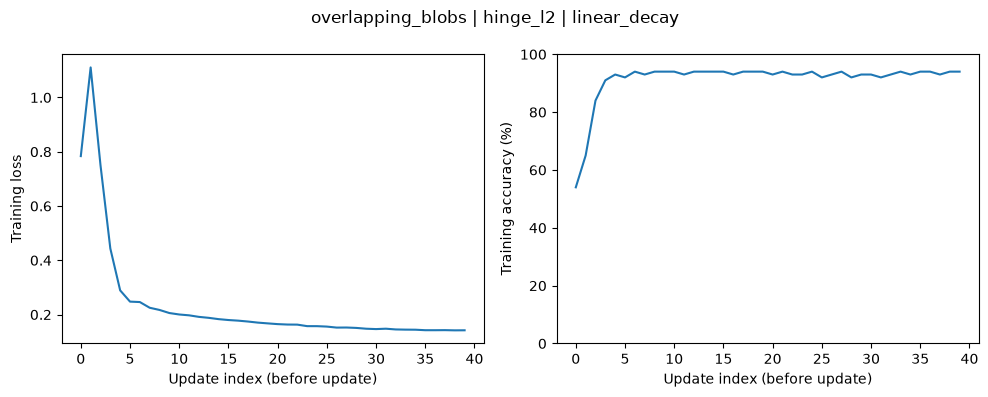

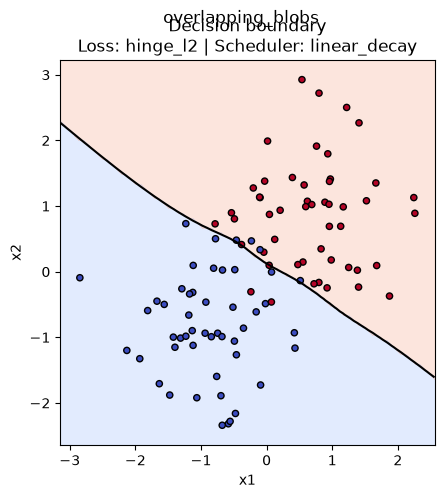

overlapping_blobs hinge_l2 constant
step 0 loss 0.78393029958802, accuracy 54.0000%
step 1 loss 1.1107284119301006, accuracy 65.0000%
step 2 loss 0.7991008132067661, accuracy 83.0000%
step 3 loss 0.46278660988587417, accuracy 91.0000%
step 4 loss 0.28770739582456917, accuracy 94.0000%
step 5 loss 0.2541902051374902, accuracy 93.0000%
step 6 loss 0.24343170256806762, accuracy 94.0000%
step 7 loss 0.23365145103861043, accuracy 93.0000%
step 8 loss 0.22230892896770482, accuracy 93.0000%
step 9 loss 0.21624577540406625, accuracy 92.0000%
step 10 loss 0.19839981222527583, accuracy 93.0000%
step 11 loss 0.1930026415494335, accuracy 93.0000%
step 12 loss 0.1873416238981347, accuracy 94.0000%
step 13 loss 0.18134454712677733, accuracy 94.0000%
step 14 loss 0.17580628694191008, accuracy 94.0000%
step 15 loss 0.17276697123169565, accuracy 94.0000%
step 16 loss 0.16891554183361962, accuracy 94.0000%
step 17 loss 0.1683045306174303, accuracy 93.0000%
step 18 loss 0.16021941017824531, accuracy 93.0

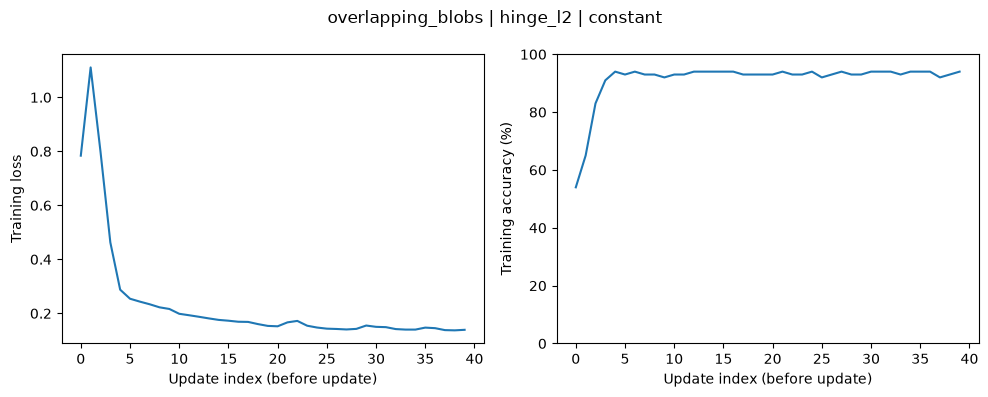

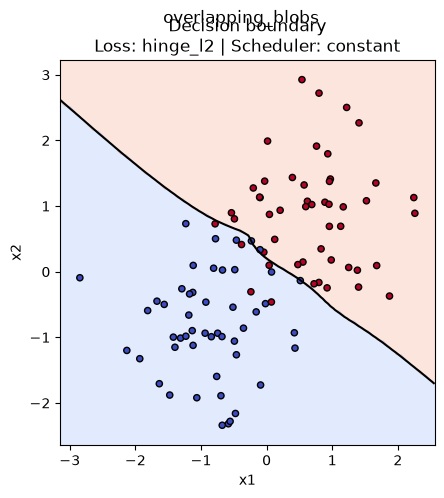

xor bce_l2 linear_decay
step 0 loss 0.8708620599981244, accuracy 49.0000%
step 1 loss 0.731401284097756, accuracy 72.0000%
step 2 loss 0.5287249657994973, accuracy 65.0000%
step 3 loss 0.41081862265125174, accuracy 75.0000%
step 4 loss 0.2034413854690178, accuracy 99.0000%
step 5 loss 0.13150906893910588, accuracy 100.0000%
step 6 loss 0.11313470799726677, accuracy 100.0000%
step 7 loss 0.10120402959781999, accuracy 100.0000%
step 8 loss 0.0920572522842808, accuracy 100.0000%
step 9 loss 0.084777008936366, accuracy 100.0000%
step 10 loss 0.07884311936228244, accuracy 100.0000%
step 11 loss 0.07392029610781575, accuracy 100.0000%
step 12 loss 0.0697783216395658, accuracy 100.0000%
step 13 loss 0.06625253155744414, accuracy 100.0000%
step 14 loss 0.06322159554118123, accuracy 100.0000%
step 15 loss 0.06059401089539099, accuracy 100.0000%
step 16 loss 0.05829944294031454, accuracy 100.0000%
step 17 loss 0.056282950837931396, accuracy 100.0000%
step 18 loss 0.05450101794782562, accuracy 10

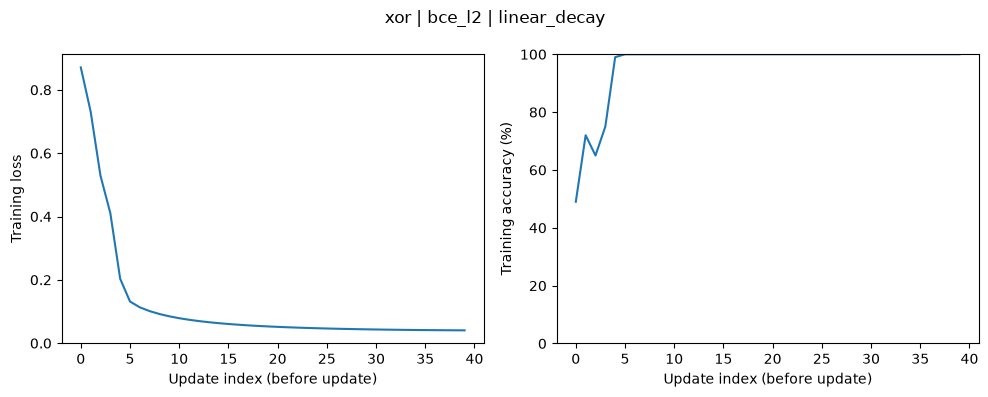

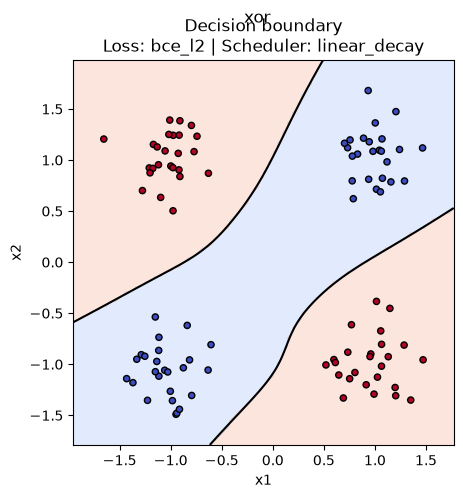

xor bce_l2 constant
step 0 loss 0.8708620599981244, accuracy 49.0000%
step 1 loss 0.731401284097756, accuracy 72.0000%
step 2 loss 0.5478676538077387, accuracy 64.0000%
step 3 loss 0.44889331558120604, accuracy 75.0000%
step 4 loss 0.21744762563686051, accuracy 99.0000%
step 5 loss 0.1287023524578908, accuracy 100.0000%
step 6 loss 0.10715429669014932, accuracy 100.0000%
step 7 loss 0.09492784825595091, accuracy 100.0000%
step 8 loss 0.08557522344298128, accuracy 100.0000%
step 9 loss 0.07810915588068595, accuracy 100.0000%
step 10 loss 0.07199990258594896, accuracy 100.0000%
step 11 loss 0.06691148467409073, accuracy 100.0000%
step 12 loss 0.06261344670769073, accuracy 100.0000%
step 13 loss 0.05894037656042815, accuracy 100.0000%
step 14 loss 0.055769849228831256, accuracy 100.0000%
step 15 loss 0.05300913797684811, accuracy 100.0000%
step 16 loss 0.05058668997709109, accuracy 100.0000%
step 17 loss 0.04844641967410676, accuracy 100.0000%
step 18 loss 0.04654376591552391, accuracy 10

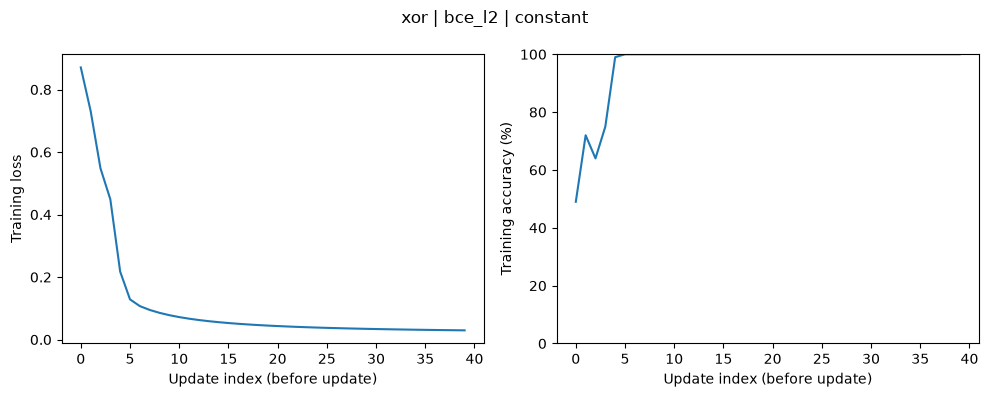

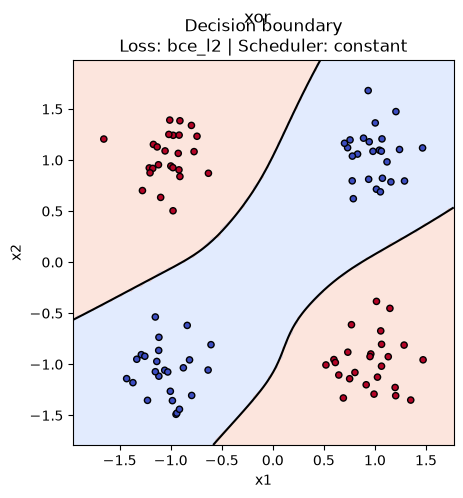

xor hinge_l2 linear_decay
step 0 loss 1.1683642444425286, accuracy 49.0000%
step 1 loss 1.4582482041189175, accuracy 67.0000%
step 2 loss 1.5211298079989295, accuracy 50.0000%
step 3 loss 0.7702929437187525, accuracy 75.0000%
step 4 loss 0.3974754738179378, accuracy 75.0000%
step 5 loss 0.7126168659466654, accuracy 75.0000%
step 6 loss 0.06203444828109515, accuracy 100.0000%
step 7 loss 0.11881356274624573, accuracy 100.0000%
step 8 loss 0.13220257346516845, accuracy 96.0000%
step 9 loss 0.025733858829460114, accuracy 100.0000%
step 10 loss 0.016690833254557436, accuracy 100.0000%
step 11 loss 0.0166856594972458, accuracy 100.0000%
step 12 loss 0.016680637491671476, accuracy 100.0000%
step 13 loss 0.016675767101088385, accuracy 100.0000%
step 14 loss 0.01667104819288515, accuracy 100.0000%
step 15 loss 0.016666480638579194, accuracy 100.0000%
step 16 loss 0.016662064313810867, accuracy 100.0000%
step 17 loss 0.016657799098337787, accuracy 100.0000%
step 18 loss 0.016653684876029425, ac

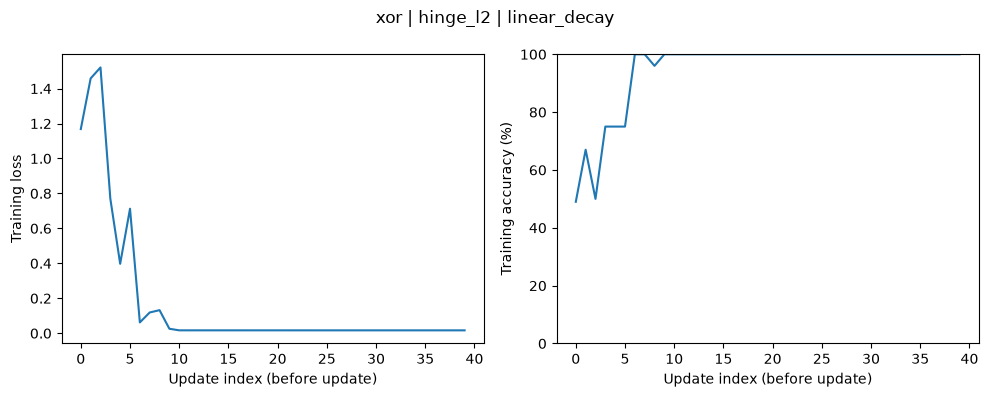

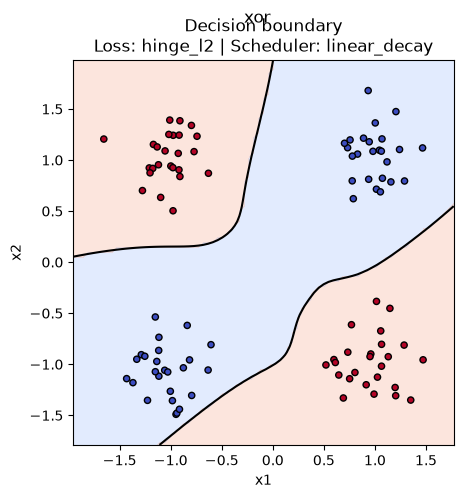

xor hinge_l2 constant
step 0 loss 1.1683642444425286, accuracy 49.0000%
step 1 loss 1.4582482041189175, accuracy 67.0000%
step 2 loss 1.56715353265064, accuracy 50.0000%
step 3 loss 0.8354739500254349, accuracy 75.0000%
step 4 loss 0.4329445631726603, accuracy 75.0000%
step 5 loss 0.8250539084578868, accuracy 75.0000%
step 6 loss 0.07337150315293582, accuracy 100.0000%
step 7 loss 0.2274726181077637, accuracy 95.0000%
step 8 loss 0.12881458641971485, accuracy 96.0000%
step 9 loss 0.023281275285067536, accuracy 100.0000%
step 10 loss 0.016789325225595546, accuracy 100.0000%
step 11 loss 0.016782610167078313, accuracy 100.0000%
step 12 loss 0.016775897794315885, accuracy 100.0000%
step 13 loss 0.016769188106234036, accuracy 100.0000%
step 14 loss 0.016762481101759104, accuracy 100.0000%
step 15 loss 0.016755776779817638, accuracy 100.0000%
step 16 loss 0.016749075139336777, accuracy 100.0000%
step 17 loss 0.016742376179244057, accuracy 100.0000%
step 18 loss 0.016735679898467384, accurac

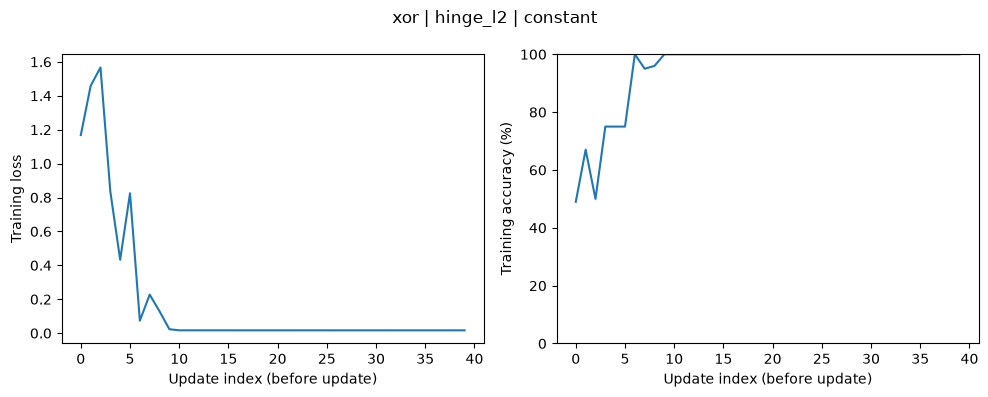

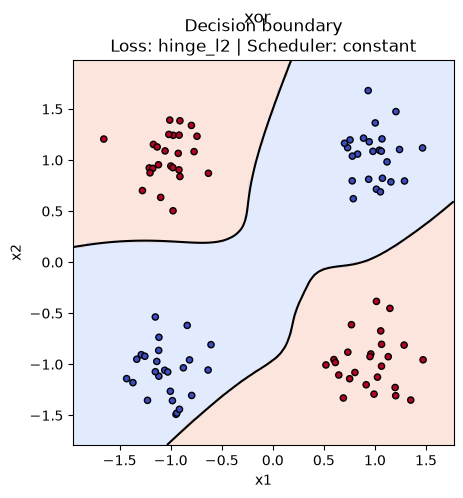

In [31]:
models: dict[str, MLP] = {}
histories: dict[str, list[tuple[Loss, Accuracy, LearningRate]]] = {}
final_metrics: dict[str, tuple[Loss, Accuracy]] = {}

for (
    (dataset_name, (X, y)),
    (loss_name, (loss_fn, acc_fn)),
    (scheduler_name, scheduler),
) in product(
    dataset_registry.items(),
    loss_and_acc_fns.items(),
    lr_scheduler.items(),
):
    print(dataset_name, loss_name, scheduler_name)

    random.seed(EXPERIMENT_SEED)
    model = MLP(2, 1, (8, 16, 16), actv_fn=lambda x: x.tanh())

    metrics = optimize(
        model, loss_fn, acc_fn, X, y,
        num_steps=40,
        learning_rate_scheduler=scheduler,
    )

    experiment_name = f"{dataset_name}_{loss_name}_{scheduler_name}"
    models[experiment_name] = model
    histories[experiment_name] = metrics
    final_scores = [model(list(map(float, row)))[0] for row in X]
    final_loss = loss_fn(model, final_scores, y).data
    final_accuracy = acc_fn(final_scores, y)
    final_metrics[experiment_name] = (final_loss, final_accuracy)
    print(f"Final training loss {final_loss}, "
          f"accuracy {final_accuracy * 100:.4f}%")

    plot_learning_curves(
        metrics, title=f"{dataset_name} | {loss_name} | {scheduler_name}"
    )
    plt.show()

    ax = plot_decision_boundary(
        model, X, y,
        loss_name=loss_name,
        scheduler_name=scheduler_name,
    )
    ax.figure.suptitle(dataset_name)
    plt.show()